# Кластеризация ЕГЭ

Рядом лежат экселевские таблицы с координатами точек. В 3 и 4 задаче используется манхетеское расстояние. В остальных Евклидово.

* Постройте Распределение точек
* Кластеризуйте руками
* Постройте Распределение точек, отметьте принадлежность кластеров цветами
* Найдите среди в каждом кластере точку расстояние от которой до всех остальных минимально
* Выведите усреднение центров всех кластеров * 1000

In [57]:
!pip install xlrd openpyxl


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [58]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from sklearn import cluster, datasets
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

In [59]:
def load_xy(path):
    path = os.path.join(r".", path)
    df = pd.read_excel(path, header=None)
    df = df.iloc[:, :2].copy()
    for c in df.columns:
        df[c] = pd.to_numeric(
            df[c].astype(str).str.replace("=", "", regex=False).str.strip(),
            errors="coerce",
        )
    return df.dropna().to_numpy(dtype=float)


def plot_clusters(X, labels, medoids=None, title="Кластеры",
                  ax=None, show_medoids=True, raw_bg=False):
    if ax is None:
        fig, ax = plt.subplots(figsize=(6.5, 5.5))

    k = int(labels.max()) + 1
    palette = plt.cm.tab10(np.linspace(0, 1, max(k, 1)))

    if raw_bg:
        ax.scatter(X[:, 0], X[:, 1], s=6, color="lightgray", zorder=0)

    for i in range(k):
        mask = labels == i
        if not mask.any():
            continue
        ax.scatter(X[mask, 0], X[mask, 1], s=14,
                   color=palette[i], label=f"Кластер {i} ({mask.sum()})")

    if show_medoids and medoids is not None:
        for i, m in enumerate(medoids):
            if m is None:
                continue
            ax.scatter(*m, marker="*", s=320, color=palette[i],
                       edgecolor="black", linewidths=1.2, zorder=5,
                       label=f"Медоид {i}")

    ax.set_title(title)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="best")
    return ax

In [60]:
def medoid(Xc, metric):
    d = cdist(Xc, Xc, metric=metric)
    return Xc[d.sum(axis=1).argmin()]


def solve(fname, rule, metric, name):
    X = load_xy(fname)

    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ax.scatter(X[:, 0], X[:, 1], s=6)
    ax.set_title(f"{name}: распределение точек")
    ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.grid(alpha=0.3)
    plt.show()

    labels = rule(X)
    k = int(labels.max()) + 1
    medoids = [medoid(X[labels == i], metric) for i in range(k)]

    plot_clusters(X, labels, medoids)
    plt.show()

    for i, m in enumerate(medoids):
        print(f"Кластер {i}: размер {np.sum(labels == i)}, центр (медоид) = ({m[0]:.6f}, {m[1]:.6f})")
    c = np.mean(medoids, axis=0)
    px, py = int(c[0] * 1000), int(c[1] * 1000)   # целая часть (отбрасывание дробной)
    print(f"Среднее центров: ({c[0]:.6f}, {c[1]:.6f})  ->  ответ: {px} {py}")
    return px, py

answers = {}

## Задача 1

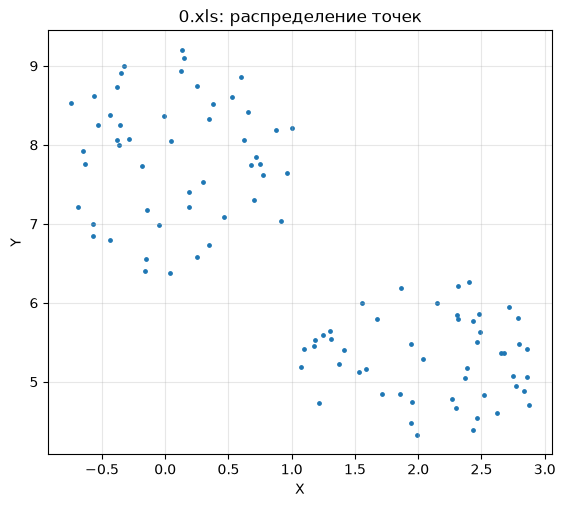

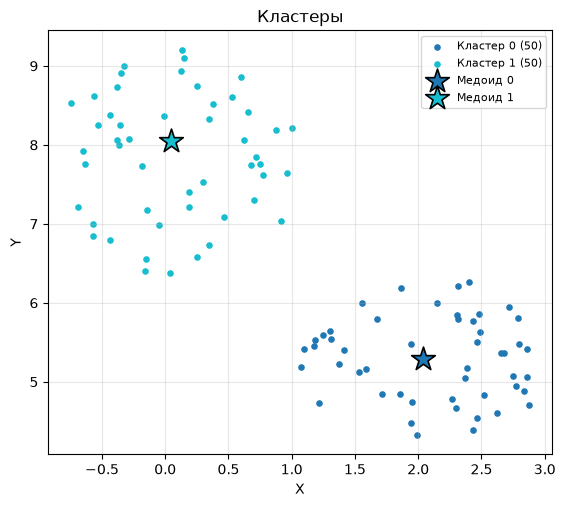

Кластер 0: размер 50, центр (медоид) = (2.033901, 5.289296)
Кластер 1: размер 50, центр (медоид) = (0.048112, 8.053051)
Среднее центров: (1.041006, 6.671173)  ->  ответ: 1041 6671


In [61]:
def rule0(X):
    x, y = X[:, 0], X[:, 1]
    return (x * 2 + 4 < y).astype(int)

answers["0.xls"] = solve("0.xls", rule0, "euclidean", "0.xls")

## Задача 2

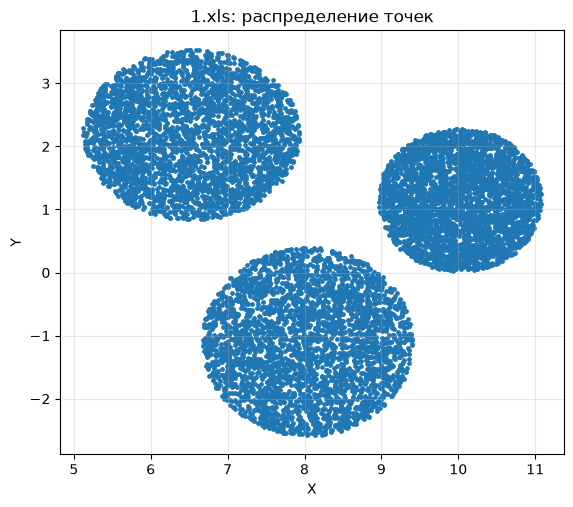

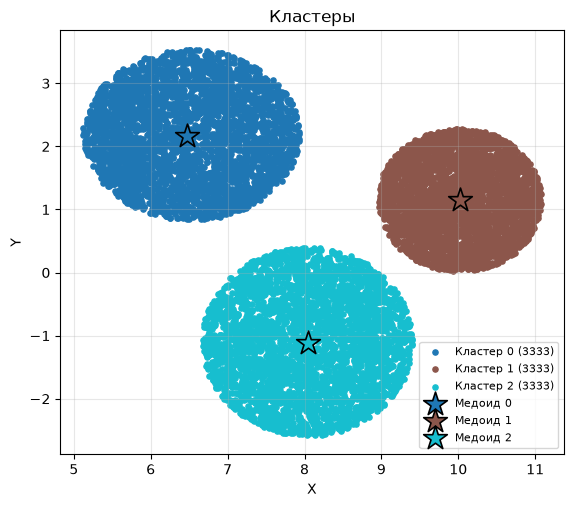

Кластер 0: размер 3333, центр (медоид) = (6.469983, 2.169761)
Кластер 1: размер 3333, центр (медоид) = (10.022535, 1.154201)
Кластер 2: размер 3333, центр (медоид) = (8.040075, -1.108706)
Среднее центров: (8.177531, 0.738419)  ->  ответ: 8177 738


In [62]:
def rule1(X):
    x, y = X[:, 0], X[:, 1]
    top_left = (x <= 8.5) & (y > 0.6)
    right = ((~top_left) & (y > 9.5 - x))
    labels = np.full(len(X), 2)
    labels[top_left] = 0                 
    labels[right] = 1         
    return labels

answers["1.xls"] = solve("1.xls", rule1, "euclidean", "1.xls")

## Задача 3

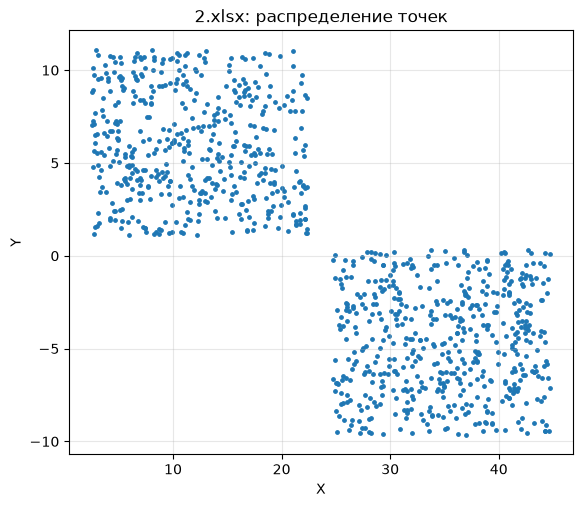

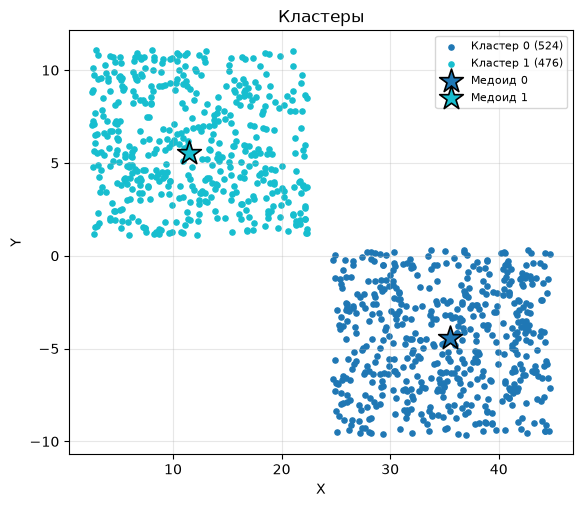

Кластер 0: размер 524, центр (медоид) = (35.516199, -4.449825)
Кластер 1: размер 476, центр (медоид) = (11.503607, 5.559190)
Среднее центров: (23.509903, 0.554682)  ->  ответ: 23509 554


In [63]:
def rule2(X):
    return (X[:, 1] > 0.5).astype(int)

answers["2.xlsx"] = solve("2.xlsx", rule2, "cityblock", "2.xlsx")

## Задача 4

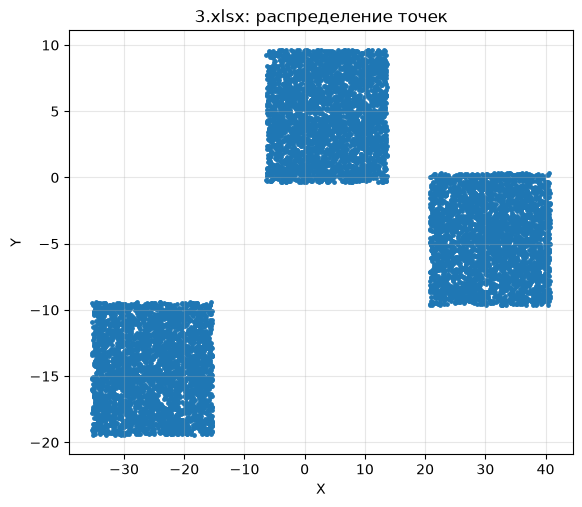

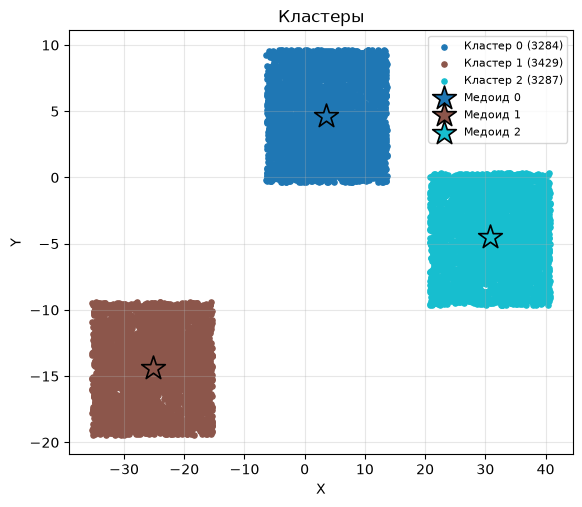

Кластер 0: размер 3284, центр (медоид) = (3.517911, 4.653696)
Кластер 1: размер 3429, центр (медоид) = (-25.130758, -14.413328)
Кластер 2: размер 3287, центр (медоид) = (30.849529, -4.517203)
Среднее центров: (3.078894, -4.758945)  ->  ответ: 3078 -4758


In [64]:
def rule3(X):
    x = X[:, 0]
    labels = np.zeros(len(X), dtype=int) 
    labels[x < -10] = 1                   
    labels[x > 18] = 2                
    return labels

answers["3.xlsx"] = solve("3.xlsx", rule3, "cityblock", "3.xlsx")

## Задача 5

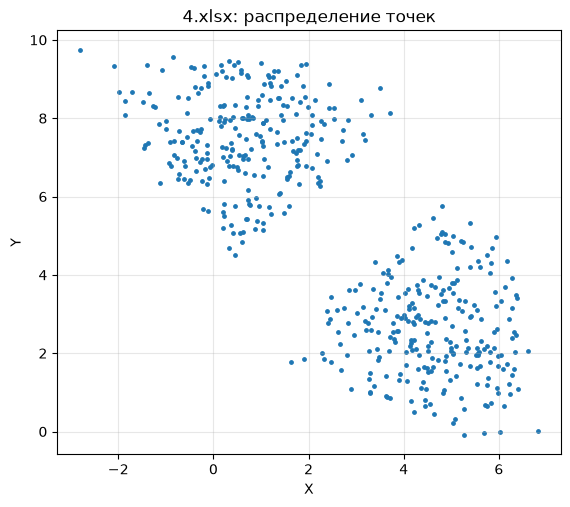

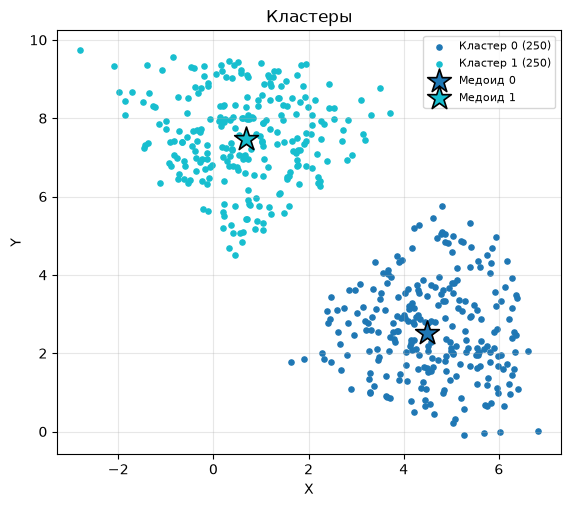

Кластер 0: размер 250, центр (медоид) = (4.499289, 2.524814)
Кластер 1: размер 250, центр (медоид) = (0.677791, 7.468321)
Среднее центров: (2.588540, 4.996568)  ->  ответ: 2588 4996


In [65]:
def rule4(X):
    x, y = X[:, 0], X[:, 1]
    return (y > 2 + x).astype(int) 

answers["4.xlsx"] = solve("4.xlsx", rule4, "euclidean", "4.xlsx")

## Задача 6

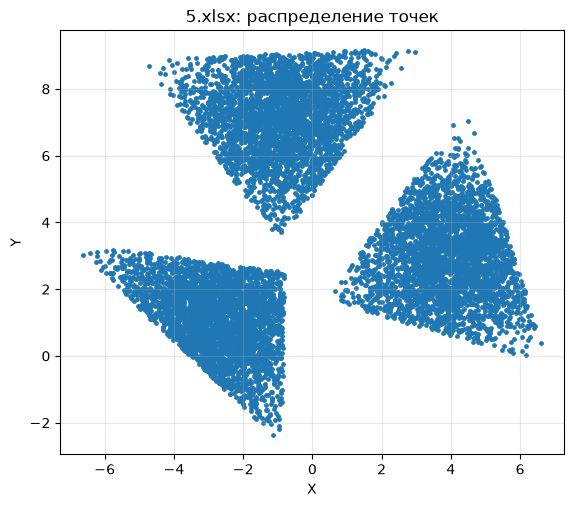

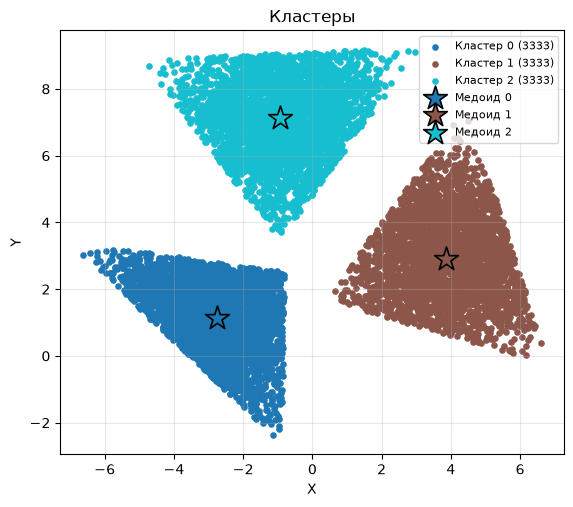

Кластер 0: размер 3333, центр (медоид) = (-2.749674, 1.143059)
Кластер 1: размер 3333, центр (медоид) = (3.858585, 2.907167)
Кластер 2: размер 3333, центр (медоид) = (-0.923954, 7.119860)
Среднее центров: (0.061652, 3.723362)  ->  ответ: 61 3723


In [66]:
def rule5(X):
    x, y = X[:, 0], X[:, 1]
    top = (y > 3.7) & (y > 4 + x)
    left = (~top) & (x < 0)                
    labels = np.full(len(X), 1)             
    labels[top] = 2
    labels[left] = 0
    return labels

answers["5.xlsx"] = solve("5.xlsx", rule5, "euclidean", "5.xlsx")

In [67]:
for f, (px, py) in answers.items():
    print(f"{f:8s} {px} {py}")

0.xls    1041 6671
1.xls    8177 738
2.xlsx   23509 554
3.xlsx   3078 -4758
4.xlsx   2588 4996
5.xlsx   61 3723


# Кластеризация sklearn (MiniBatchKMeans и DBSCAN)

Для каждой пары алгоритм–данные строим график, кластеры раскрашены разными цветами (шум DBSCAN — чёрным). Число кластеров для KMeans задаётся равным «истинному» (2 для circles/moons, 3 для остальных), `eps` для DBSCAN подобран под каждый набор.

In [68]:
np.random.seed(42)

n_samples = 1500
noisy_circles = datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05)
noisy_moons = datasets.make_moons(n_samples=n_samples, noise=0.05)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=8)
no_structure = np.random.rand(n_samples, 2), None

random_state = 170
X, y = datasets.make_blobs(n_samples=n_samples, random_state=random_state)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)
aniso = (X_aniso, y)

varied = datasets.make_blobs(
    n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state
)

default_base = {
    "quantile": 0.3, "eps": 0.3, "damping": 0.9, "preference": -200,
    "n_neighbors": 10, "n_clusters": 3, "min_samples": 20,
    "xi": 0.05, "min_cluster_size": 0.1,
}

data_sets = [
    ("noisy_circles", noisy_circles, {"n_clusters": 2, "eps": 0.2}),
    ("noisy_moons", noisy_moons, {"n_clusters": 2, "eps": 0.2}),
    ("varied", varied, {"eps": 0.18}),
    ("aniso", aniso, {"eps": 0.15}),
    ("blobs", blobs, {"eps": 0.3}),
    ("no_structure", no_structure, {"eps": 0.3}),
]

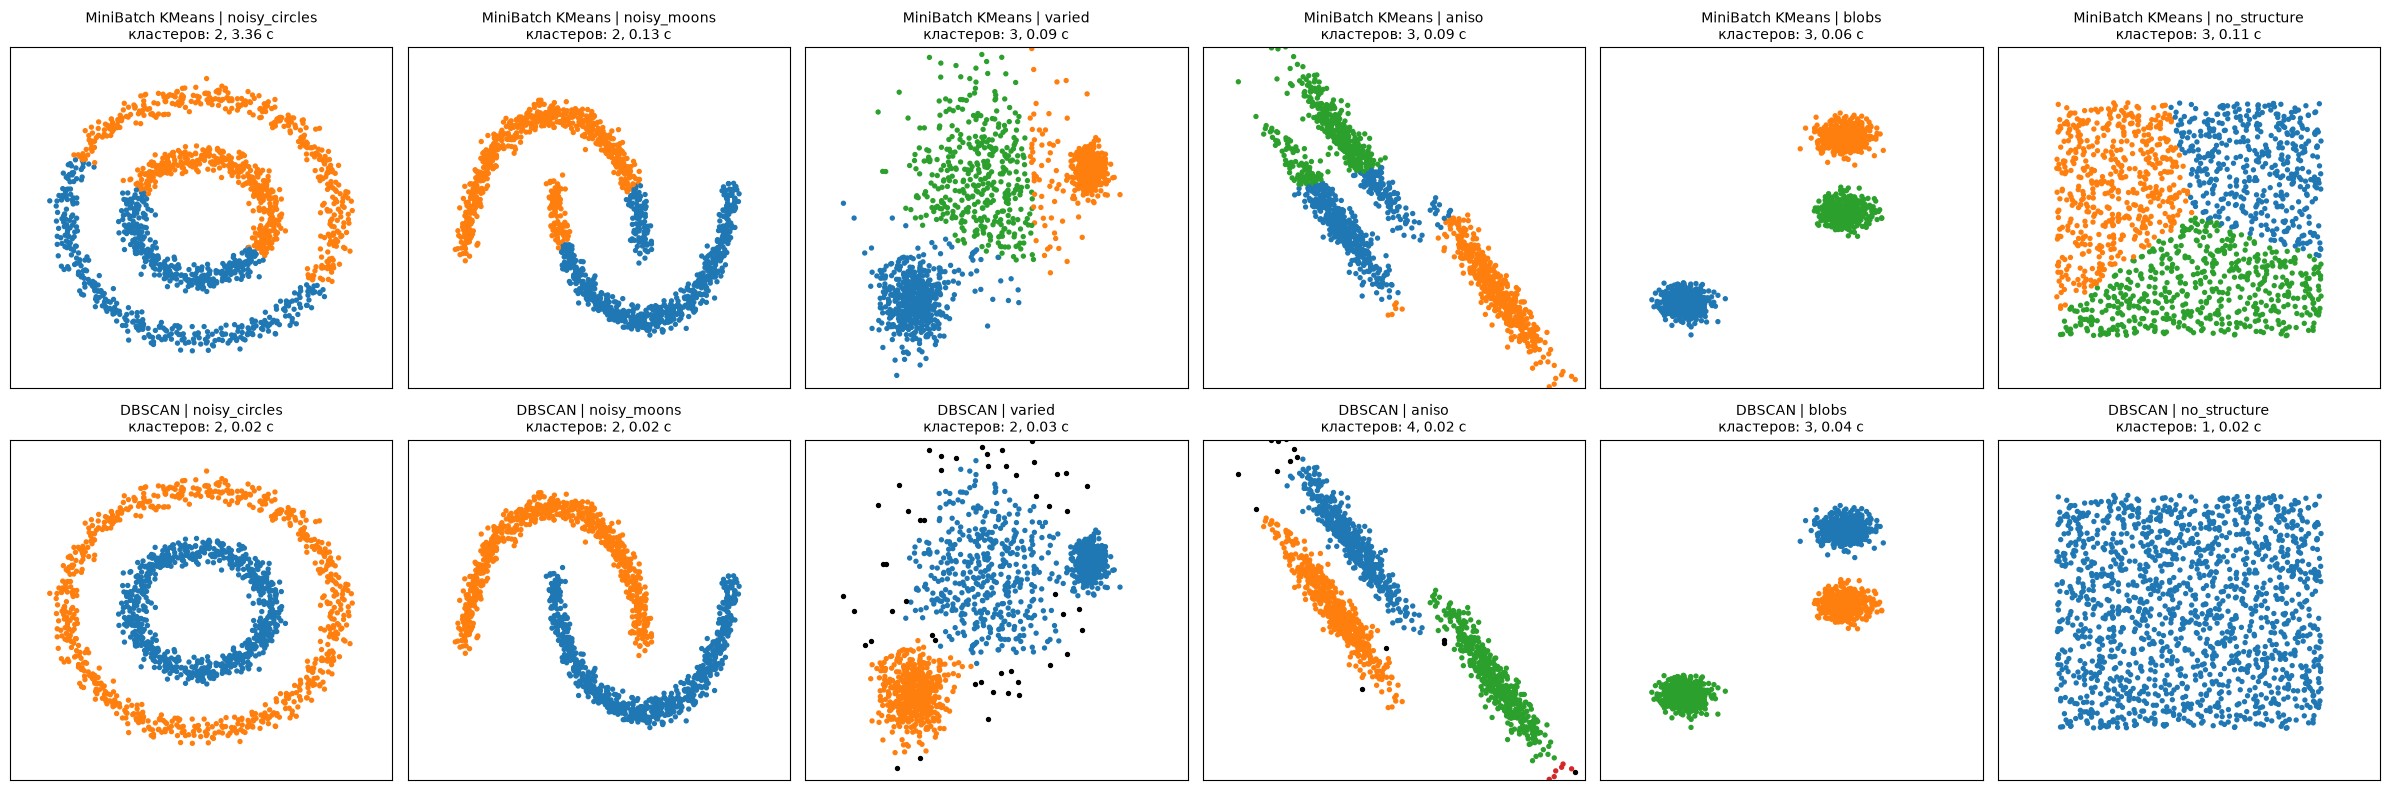

In [69]:
def make_algorithms(params):
    two_means = cluster.MiniBatchKMeans(
        n_clusters=params["n_clusters"], n_init="auto", random_state=0
    )
    dbscan = cluster.DBSCAN(eps=params["eps"])
    return (
        ("MiniBatch\nKMeans", two_means),
        ("DBSCAN", dbscan),
    )

clustering_algorithms = make_algorithms(default_base)

colors = plt.cm.tab10(np.arange(10))

fig, axes = plt.subplots(len(clustering_algorithms), len(data_sets), figsize=(4 * len(data_sets), 8))

for j, (ds_name, (X, y), algo_params) in enumerate(data_sets):
    params = default_base.copy()
    params.update(algo_params)
    X = StandardScaler().fit_transform(X)

    for i, (name, algorithm) in enumerate(make_algorithms(params)):
        t0 = time.time()
        algorithm.fit(X)
        dt = time.time() - t0
        labels = algorithm.labels_.astype(int)

        ax = axes[i, j]
        noise = labels == -1
        ax.scatter(X[~noise, 0], X[~noise, 1], s=8, color=colors[labels[~noise] % 10])
        if noise.any():
            ax.scatter(X[noise, 0], X[noise, 1], s=8, color="black", label="шум")
        n_found = len(set(labels) - {-1})
        ax.set_title(f"{name.replace(chr(10), ' ')} | {ds_name}\nкластеров: {n_found}, {dt:.2f} c", fontsize=10)
        ax.set_xlim(-2.5, 2.5); ax.set_ylim(-2.5, 2.5)
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()